
### Feature Audit and Engineering

#### Project Objective

The objective of this notebook is to audit the available transaction features and create additional feature representations for the credit card fraud detection model.

Building on the findings from exploratory data analysis and statistical analysis, we will review the available features, assess their suitability for modelling, perform justified feature engineering, and implement the necessary preprocessing steps.

Our goal is to make evidence-informed feature engineering decisions while keeping the original features available for comparison. Encoding, scaling, and model-ready preprocessing pipelines will be handled in the modelling-preparation phase.

#### Workflow

1. Feature audit
2. Initial feature assessment
3. Feature engineering
4. Verification of engineered features

**Next phase:** categorical encoding, scaling where needed, preprocessing pipelines, and training/validation preparation.


## 1. Feature Audit and Initial Assessment

Before creating new features, we first inspect the training and test datasets to understand what is available and whether the two datasets have a consistent structure.

The target, `is_fraud`, is present only in the training data. This is expected because the test dataset is reserved for making predictions.

The audit checks:
- Dataset dimensions and duplicate rows.
- Differences between training and test columns.
- Data types and feature roles.
- Missing values, number of unique values, and constant columns.

This gives us an initial overview before deciding which features need further investigation.


In [43]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [44]:
# Define project paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load datasets
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# Inspect dataset dimensions
print(f"Training data shape: {train_df.shape}")
print(f"Test data shape: {test_df.shape}")


Training data shape: (699960, 26)
Test data shape: (299984, 25)


In [45]:
def feature_audit(train_df, test_df, target="is_fraud", id_col="id"):

    # Check dataset overview
    print("DATASET OVERVIEW")
    print("-" * 50)
    print(f"Training shape: {train_df.shape}")
    print(f"Test shape:     {test_df.shape}")
    print(f"Duplicate rows in train: {train_df.duplicated().sum()}")
    print(f"Duplicate rows in test:  {test_df.duplicated().sum()}")

    # Check column consistency
    train_only = set(train_df.columns) - set(test_df.columns)
    test_only = set(test_df.columns) - set(train_df.columns)

    print("\nCOLUMN CONSISTENCY")
    print("-" * 50)
    print(f"Columns only in train: {train_only}")
    print(f"Columns only in test:  {test_only}")

    # Build feature audit
    audit = []

    for col in train_df.columns:

        series = train_df[col]

        if col == id_col:
            role = "Identifier"
        elif col == target:
            role = "Target"
        elif pd.api.types.is_bool_dtype(series):
            role = "Boolean"
        elif pd.api.types.is_numeric_dtype(series):
            role = "Numerical"
        else:
            role = "Categorical"

        audit.append({
            "feature": col,
            "dtype": str(series.dtype),
            "role": role,
            "missing": series.isna().sum(),
            "missing_%": round(series.isna().mean() * 100, 2),
            "unique_values": series.nunique(),
            "constant": series.nunique() <= 1,
            "sample_values": series.dropna().unique()[:5].tolist()
        })

    audit_df = pd.DataFrame(audit)

    display(audit_df)

    return audit_df

In [46]:
feature_audit_df = feature_audit(train_df, test_df)

DATASET OVERVIEW
--------------------------------------------------
Training shape: (699960, 26)
Test shape:     (299984, 25)
Duplicate rows in train: 0
Duplicate rows in test:  0

COLUMN CONSISTENCY
--------------------------------------------------
Columns only in train: {'is_fraud'}
Columns only in test:  set()


,feature,dtype,role,missing,missing_%,unique_values,constant,sample_values
0,id,int64,Identifier,0,0.0,699960,False,"[0, 1, 2, 3, 4]"
1,amount_usd,float64,Numerical,0,0.0,13387,False,"[61.16, 24.83, 6.36, 37.44, 653.85]"
2,hours_since_last_txn,float64,Numerical,0,0.0,3633,False,"[9.77, 1.54, 1.2, 5.13, 0.8]"
3,txn_count_last_24h,int64,Numerical,0,0.0,12,False,"[1, 3, 4, 6, 5]"
4,distance_from_home_km,float64,Numerical,0,0.0,4365,False,"[17.78, 13.06, 8.17, 8.67, 11.69]"
5,card_age_months,int64,Numerical,0,0.0,49,False,"[48, 38, 50, 37, 51]"
6,customer_age,int64,Numerical,0,0.0,64,False,"[56, 28, 55, 48, 52]"
7,account_balance_usd,float64,Numerical,0,0.0,43317,False,"[1269.35, 3233.0, 1046.88, 2217.67, 3291.06]"
8,cvv_retry_count,int64,Numerical,0,0.0,4,False,"[0, 1, 2, 3]"
9,velocity_score,float64,Numerical,0,0.0,666,False,"[5.5, 33.4, 35.8, 20.7, 34.8]"


### Numerical Feature Distributions and Outlier Checks

We begin by reviewing summary statistics for the numerical features. The table includes the count, mean, standard deviation, quartiles, minimum, and maximum.

We then calculate skewness and use the IQR rule to flag potential outliers.

For this check, a value is flagged when it falls below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

**Important:** These are potential outliers, not automatically erroneous records. In fraud detection, unusually large transaction amounts or other extreme values may carry useful information. We therefore inspect the distributions rather than removing or capping these values automatically.


In [47]:
numeric_features = train_df.select_dtypes(include="number").columns.drop(
    ["id", "is_fraud"]
)

display(
    train_df[numeric_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


In [48]:
numeric_audit = train_df[numeric_features].agg(
    ["skew", "min", "max"]
).T

Q1 = train_df[numeric_features].quantile(0.25)
Q3 = train_df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (train_df[numeric_features] < lower_bound) |
    (train_df[numeric_features] > upper_bound)
).sum()

numeric_audit["outlier_count"] = outlier_count
numeric_audit["outlier_%"] = (
    outlier_count / len(train_df) * 100
).round(2)

display(numeric_audit.round(3))

,skew,min,max,outlier_count,outlier_%
amount_usd,7.002,1.00,6872.69,70741,10.11
hours_since_last_txn,1.823,0.01,51.98,32816,4.69
txn_count_last_24h,0.436,0.00,11.00,2704,0.39
distance_from_home_km,1.060,0.00,57.93,16770,2.40
card_age_months,0.133,25.00,73.00,2253,0.32
customer_age,-0.141,18.00,81.00,0,0.00
account_balance_usd,14.436,58.25,99701.39,29068,4.15
cvv_retry_count,3.319,0.00,3.00,57872,8.27
velocity_score,0.260,0.00,72.90,4276,0.61
time_of_day_hour,-0.056,0.00,23.00,0,0.00


### Count Feature Distributions

We inspect the value frequencies of `cvv_retry_count` and `prior_disputes`.

Most transactions have zero CVV retries (91.73%), while 85.49% have no prior disputes. The remaining observations are concentrated at small count values.

This tells us that the two features are zero-heavy. It also gives us a reason to investigate whether a simpler indicator—whether any retry or dispute has occurred—could provide a useful additional representation.

We retain the original counts so that the exact number of retries or disputes is not lost.


In [49]:
count_features = ["cvv_retry_count", "prior_disputes"]

for col in count_features:
    print(f"\n{col}")
    display(
        train_df[col]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .rename("percentage")
        .to_frame()
    )


cvv_retry_count


,percentage
cvv_retry_count,
0,91.73
1,7.99
2,0.27
3,0.00



prior_disputes


,percentage
prior_disputes,
0,85.49
1,13.77
2,0.72
3,0.02
4,0.00


### Categorical Feature Distributions

Next, we inspect the frequency distribution of each categorical feature.

This helps us understand:
- How many categories each feature contains.
- Which categories are common or uncommon.
- Whether some categories occur very infrequently.

These checks will be useful when choosing an encoding approach during modelling preparation. At this stage, we are only inspecting the categories; no encoding has been applied yet.


In [50]:
categorical_features = train_df.select_dtypes(
    include=["object", "str"]
).columns

for col in categorical_features:
    print(f"\n{col} — {train_df[col].nunique()} categories")

    display(
        train_df[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename("percentage")
        .to_frame()
    )


merchant_category — 12 categories


,percentage
merchant_category,
Online Retail,22.16
Groceries,20.37
Restaurants,14.48
Fuel,8.55
Electronics,6.96
Streaming,6.74
Utilities,6.00
Healthcare,5.13
Travel,4.10



card_type — 5 categories


,percentage
card_type,
Visa,49.29
Mastercard,36.41
Amex,6.54
RuPay,5.30
Discover,2.46



auth_method — 5 categories


,percentage
auth_method,
3D Secure,30.01
OTP,25.03
PIN,22.00
Biometric,13.38
No Authentication,9.58



channel — 5 categories


,percentage
channel,
Online,39.14
POS,29.50
Contactless,15.09
In-App,11.96
ATM,4.32



device_type — 8 categories


,percentage
device_type,
Android Phone,33.92
iPhone,23.53
POS Terminal,16.18
Windows PC,11.56
Mac,4.85
Tablet,3.96
Smart Watch,3.02
ATM Machine,2.98


### Boolean Feature Distributions

The Boolean features already contain two values: `True` and `False`.

We inspect their proportions to understand how frequently each condition occurs. Several conditions are relatively uncommon—for example, `is_ai_generated_scam_attempt` is `True` for only 0.33% of transactions.

Because these features are already binary, they can be retained in their current form for the initial modelling experiments.


In [51]:
boolean_features = train_df.select_dtypes(
    include="bool"
).columns

for col in boolean_features:
    print(f"\n{col}")

    display(
        train_df[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename("percentage")
        .to_frame()
    )


is_foreign_transaction


,percentage
is_foreign_transaction,
False,98.27
True,1.73



is_new_merchant


,percentage
is_new_merchant,
False,84.75
True,15.25



used_vpn


,percentage
used_vpn,
False,96.62
True,3.38


... (2 outputs left out)


billing_shipping_mismatch


,percentage
billing_shipping_mismatch,
False,98.71
True,1.29



is_ai_generated_scam_attempt


,percentage
is_ai_generated_scam_attempt,
False,99.67
True,0.33


### Boolean Features and Observed Fraud Rates

A feature's frequency alone does not tell us whether it may be useful for distinguishing fraudulent transactions. We therefore compare the observed fraud rate for the `True` and `False` groups of each Boolean feature.

The `difference_pp` column is the difference between those two rates, expressed in percentage points. For example, the 15.07 value for `ip_country_mismatch` means that the observed fraud rate in the `True` group is 15.07 percentage points higher than in the `False` group.

These are descriptive comparisons, not proof that a condition causes fraud. Rare groups should also be interpreted with their sample sizes in mind.

**Decision:** Retain all six Boolean features as candidates and assess their contribution using validation data during modelling.


In [52]:
fraud_rate_summary = []

for col in boolean_features:
    rates = train_df.groupby(col, observed=True)["is_fraud"].mean()

    fraud_rate_summary.append({
        "feature": col,
        "fraud_rate_false_%": rates.get(False, 0) * 100,
        "fraud_rate_true_%": rates.get(True, 0) * 100,
        "difference_pp": (
            rates.get(True, 0) - rates.get(False, 0)
        ) * 100
    })

fraud_rate_summary = pd.DataFrame(fraud_rate_summary)

display(
    fraud_rate_summary
    .round(2)
    .sort_values("difference_pp", ascending=False)
)

,feature,fraud_rate_false_%,fraud_rate_true_%,difference_pp
3,ip_country_mismatch,1.43,16.50,15.07
5,is_ai_generated_scam_attempt,1.63,15.22,13.60
4,billing_shipping_mismatch,1.52,12.99,11.47
0,is_foreign_transaction,1.48,12.57,11.09
2,used_vpn,1.50,6.55,5.05
1,is_new_merchant,1.12,4.73,3.62


#### Boolean Feature Analysis

All six Boolean features have higher observed fraud rates when their value is `True`.

The strongest differences were observed in:

- `ip_country_mismatch`: 15.07 percentage points.
- `is_ai_generated_scam_attempt`: 13.60 percentage points.
- `billing_shipping_mismatch`: 11.47 percentage points.
- `is_foreign_transaction`: 11.09 percentage points.

`is_ai_generated_scam_attempt` is particularly worth monitoring because, despite its strong association with fraud, it occurs in only a small proportion of transactions.

**Decision:** Retain all six Boolean features in their original binary form. Their predictive contribution will be evaluated during model development.

## 2. Feature Engineering

The initial audit did not indicate that we should remove the unusual numerical values or discard the existing features. Instead, we create a small set of additional representations that may help models capture useful patterns.

The engineered features are added to copies of the original datasets:
- `train_fe` for the training data.
- `test_fe` for the test data.

The same feature definitions are applied to both datasets. The target remains in the training data only.


In [53]:
train_fe = train_df.copy()
test_fe = test_df.copy()

for df in [train_fe, test_fe]:
    df["has_cvv_retry"] = (df["cvv_retry_count"] > 0).astype("int8")
    df["has_prior_dispute"] = (df["prior_disputes"] > 0).astype("int8")

In [54]:
display(
    train_fe[
        [
            "cvv_retry_count",
            "has_cvv_retry",
            "prior_disputes",
            "has_prior_dispute",
        ]
    ].head(10)
)

print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

,cvv_retry_count,has_cvv_retry,prior_disputes,has_prior_dispute
0,0,0,0,0
1,0,0,1,1
2,0,0,0,0
3,0,0,0,0
4,0,0,0,0
5,0,0,0,0
6,0,0,0,0
7,0,0,0,0
8,0,0,0,0
9,0,0,0,0


Training shape: (699960, 28)
Test shape: (299984, 27)


#### Binary Indicator Features

Created two binary features:

- `has_cvv_retry`: 1 if `cvv_retry_count` is greater than zero, otherwise 0.
- `has_prior_dispute`: 1 if `prior_disputes` is greater than zero, otherwise 0.

The original count features were retained to preserve information about the number of retries and disputes.

**Decision:** Keep both the original count features and their corresponding binary indicators for model evaluation.

In [55]:
for df in [train_fe, test_fe]:
    # Hour of the day (24-hour cycle)
    df["hour_sin"] = np.sin(2 * np.pi * df["time_of_day_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["time_of_day_hour"] / 24)

    # Day of the week (7-day cycle)
    df["day_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["day_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

In [56]:
display(
    train_fe[
        [
            "time_of_day_hour",
            "hour_sin",
            "hour_cos",
            "day_of_week",
            "day_sin",
            "day_cos",
        ]
    ].head(10).round(4)
)

print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

,time_of_day_hour,hour_sin,hour_cos,day_of_week,day_sin,day_cos
0,17,-0.9659,-0.2588,3,0.4339,-0.9010
1,23,-0.2588,0.9659,5,-0.9749,-0.2225
2,15,-0.7071,-0.7071,0,0.0000,1.0000
3,7,0.9659,-0.2588,3,0.4339,-0.9010
4,4,0.8660,0.5000,4,-0.4339,-0.9010
5,17,-0.9659,-0.2588,0,0.0000,1.0000
6,17,-0.9659,-0.2588,5,-0.9749,-0.2225
7,22,-0.5000,0.8660,4,-0.4339,-0.9010
8,9,0.7071,-0.7071,2,0.9749,-0.2225
9,6,1.0000,0.0000,3,0.4339,-0.9010


Training shape: (699960, 32)
Test shape: (299984, 31)


### Cyclical Feature Engineering

Created four cyclical features using sine and cosine transformations:

- `hour_sin` and `hour_cos` represent the 24-hour daily cycle.
- `day_sin` and `day_cos` represent the 7-day weekly cycle.

These transformations preserve the circular relationship between time values. For example, hour 23 is close to hour 0, rather than being treated as numerically far away.

**Decision:** Retain the four engineered features alongside the original time columns for now. We will evaluate their usefulness during model development.

### Log Transformations: Transaction Amount and Account Balance

The earlier numerical audit showed strong positive skewness in `amount_usd` and `account_balance_usd`. Their distributions contain many relatively small values and a smaller number of very large values.

We apply `np.log1p()` to create additional versions of these features. `log1p(x)` calculates `log(1 + x)`, which also handles zero values safely.

We first check that both features are non-negative, because this transformation is intended for values greater than or equal to zero.

The original columns are kept. The transformed columns are additional candidates, not replacements.


In [57]:
train_fe[
    ["amount_usd", "account_balance_usd"]
].min()

amount_usd              1.00
account_balance_usd    58.25
dtype: float64

In [58]:
for df in [train_fe, test_fe]:
    df["amount_usd_log"] = np.log1p(df["amount_usd"])
    df["account_balance_usd_log"] = np.log1p(
        df["account_balance_usd"]
    )

In [59]:
display(
    train_fe[
        [
            "amount_usd",
            "amount_usd_log",
            "account_balance_usd",
            "account_balance_usd_log",
        ]
    ].describe().round(3)
)

print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

,amount_usd,amount_usd_log,account_balance_usd,account_balance_usd_log
count,699960.000,699960.000,699960.000,699960.000
mean,79.893,3.456,2064.998,7.302
std,205.174,1.075,3400.133,0.729
min,1.000,0.693,58.250,4.082
25%,15.810,2.822,834.120,6.728
50%,27.250,3.341,1382.740,7.233
75%,43.110,3.787,2517.020,7.831
max,6872.690,8.835,99701.390,11.510


Training shape: (699960, 34)
Test shape: (299984, 33)


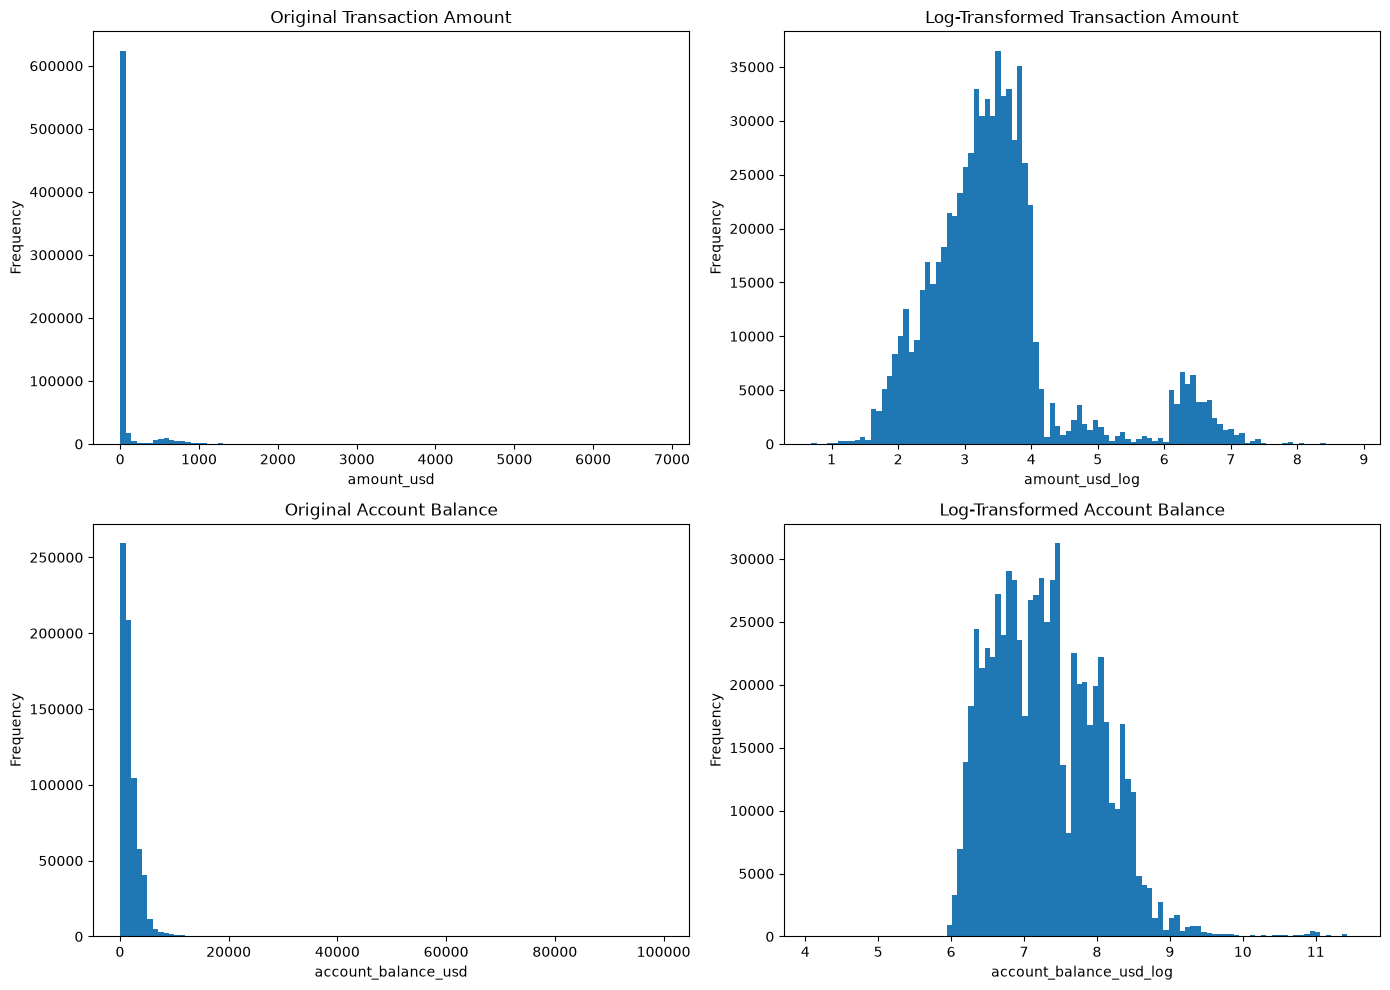

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

columns = [
    ("amount_usd", "Original Transaction Amount"),
    ("amount_usd_log", "Log-Transformed Transaction Amount"),
    ("account_balance_usd", "Original Account Balance"),
    ("account_balance_usd_log", "Log-Transformed Account Balance"),
]

for ax, (col, title) in zip(axes.flat, columns):
    ax.hist(train_fe[col], bins=100)
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [61]:
skewness_comparison = pd.DataFrame({
    "original_skewness": train_fe[
        ["amount_usd", "account_balance_usd"]
    ].skew(),
    "transformed_skewness": train_fe[
        ["amount_usd_log", "account_balance_usd_log"]
    ].skew().values
})

display(skewness_comparison.round(4))

,original_skewness,transformed_skewness
amount_usd,7.0022,1.4458
account_balance_usd,14.4362,0.6542


### Log Transformation Results

Applied `np.log1p()` to `amount_usd` and `account_balance_usd`.

The transformations substantially reduced positive skewness:

| Feature | Original Skewness | Transformed Skewness |
|---|---:|---:|
| `amount_usd` | 7.0022 | 1.4458 |
| `account_balance_usd` | 14.4362 | 0.6542 |

The histograms also showed a more compact distribution after transformation.

**Decision:** Retain both original and log-transformed features for subsequent model evaluation. We will determine their predictive usefulness using validation performance rather than skewness alone.

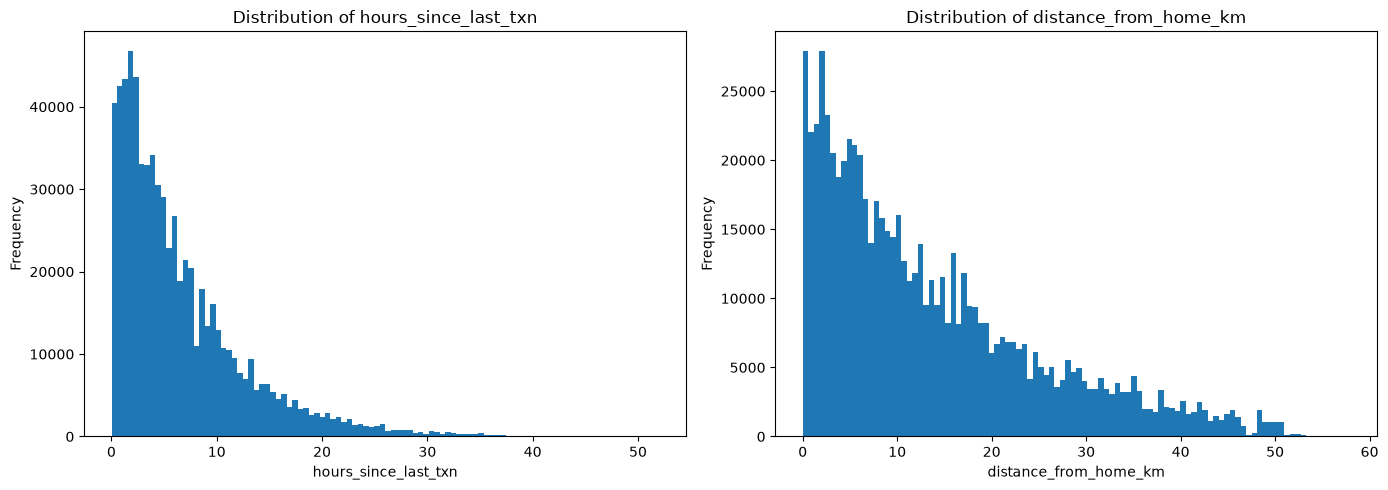

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

columns = [
    "hours_since_last_txn",
    "distance_from_home_km"
]

for ax, col in zip(axes, columns):
    ax.hist(train_fe[col], bins=100)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [63]:
train_fe[
    ["hours_since_last_txn", "distance_from_home_km"]
].agg(["min", "max", "mean", "median"])

,hours_since_last_txn,distance_from_home_km
min,0.010000,0.000000
max,51.980000,57.930000
mean,6.633734,13.587575
median,4.730000,10.220000


In [64]:
for df in [train_fe, test_fe]:
    df["hours_since_last_txn_log"] = np.log1p(
        df["hours_since_last_txn"]
    )

    df["distance_from_home_km_log"] = np.log1p(
        df["distance_from_home_km"]
    )

In [65]:
display(
    train_fe[
        [
            "hours_since_last_txn",
            "hours_since_last_txn_log",
            "distance_from_home_km",
            "distance_from_home_km_log",
        ]
    ].describe().round(3)
)

print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

,hours_since_last_txn,hours_since_last_txn_log,distance_from_home_km,distance_from_home_km_log
count,699960.000,699960.000,699960.000,699960.000
mean,6.634,1.728,13.588,2.311
std,6.290,0.795,11.617,0.934
min,0.010,0.010,0.000,0.000
25%,2.110,1.135,4.430,1.692
50%,4.730,1.746,10.220,2.418
75%,9.190,2.321,19.750,3.033
max,51.980,3.970,57.930,4.076


Training shape: (699960, 36)
Test shape: (299984, 35)


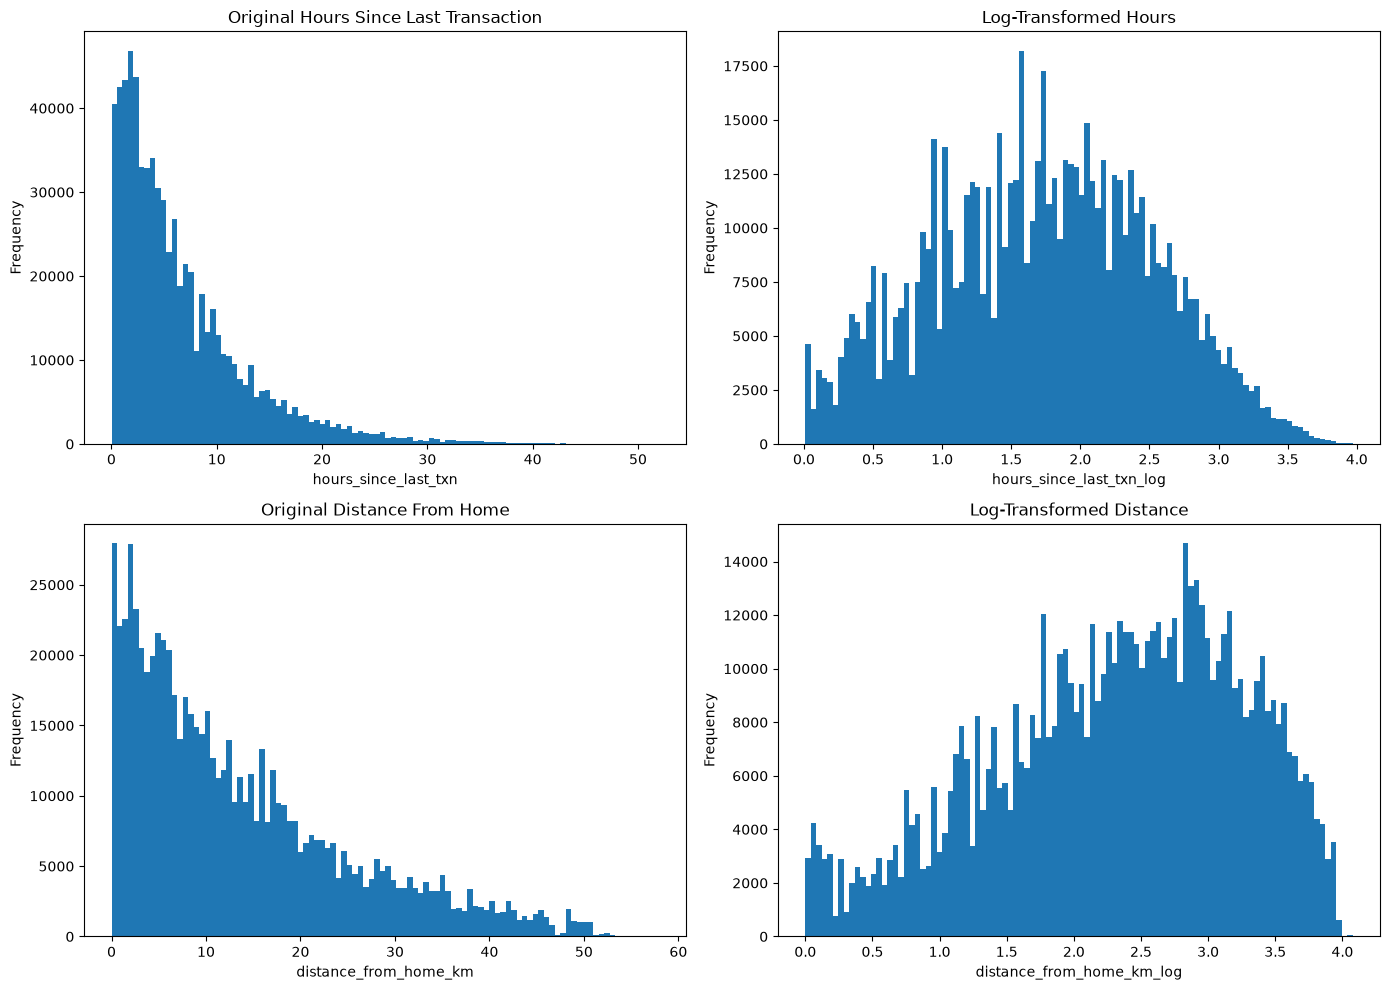

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

columns = [
    ("hours_since_last_txn", "Original Hours Since Last Transaction"),
    ("hours_since_last_txn_log", "Log-Transformed Hours"),
    ("distance_from_home_km", "Original Distance From Home"),
    ("distance_from_home_km_log", "Log-Transformed Distance"),
]

for ax, (col, title) in zip(axes.flat, columns):
    ax.hist(train_fe[col], bins=100)
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [67]:
skewness_comparison = pd.DataFrame({
    "original_skewness": train_fe[
        ["hours_since_last_txn", "distance_from_home_km"]
    ].skew().values,
    "transformed_skewness": train_fe[
        ["hours_since_last_txn_log", "distance_from_home_km_log"]
    ].skew().values
}, index=["hours_since_last_txn", "distance_from_home_km"])

display(skewness_comparison.round(4))

,original_skewness,transformed_skewness
hours_since_last_txn,1.8232,-0.0224
distance_from_home_km,1.0597,-0.4390


### Log Transformation: Time Since Transaction and Distance

Applied `np.log1p()` to:

- `hours_since_last_txn`
- `distance_from_home_km`

The transformations reduced the positive skewness considerably.

| Feature | Original Skewness | Transformed Skewness |
|---|---:|---:|
| `hours_since_last_txn` | 1.8232 | -0.0224 |
| `distance_from_home_km` | 1.0597 | -0.4390 |

The transformed hours feature is now approximately symmetric, while distance has become mildly left-skewed.

**Decision:** Retain both original and transformed versions as candidates. Their usefulness will be evaluated during model development.

The transformations are not assumed to improve predictive performance simply because they reduce skewness.

### Investigating Potential Feature Interactions

Some fraud-related signals may be more informative when they occur together. We investigate two combinations:

- A foreign transaction together with an IP-country mismatch.
- VPN usage together with an IP-country mismatch.

For each combination, we group the training observations by the two Boolean conditions and calculate the number of transactions and the observed fraud rate.

The group counts matter: a high fraud rate in a very small group may be less stable than a similar rate based on many observations. These comparisons help us decide whether to create interaction features for later model evaluation; they do not establish causation.


In [68]:
display(
    train_df.groupby(
        ["is_foreign_transaction", "ip_country_mismatch"],
        observed=True
    )["is_fraud"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "fraud_rate"})
    .assign(fraud_rate=lambda x: x["fraud_rate"] * 100)
    .round(2)
)

count  fraud_rate
is_foreign_transaction ip_country_mismatch                    
False                  False                680081        1.36
                       True                   7781       12.23
True                   False                  8567        7.09
                       True                   3531       25.89

In [69]:
df["foreign_ip_mismatch"] = (
    df["is_foreign_transaction"] &
    df["ip_country_mismatch"]
).astype("int8")

In [70]:
display(
    train_df.groupby(
        ["used_vpn", "ip_country_mismatch"],
        observed=True
    )["is_fraud"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "fraud_rate"})
    .assign(fraud_rate=lambda x: x["fraud_rate"] * 100)
    .round(2)
)

count  fraud_rate
used_vpn ip_country_mismatch                    
False    False                665571        1.28
         True                  10724       15.00
True     False                 23077        5.60
         True                    588       43.71

In [71]:
for df in [train_fe, test_fe]:
    df["foreign_ip_mismatch"] = (
        df["is_foreign_transaction"] &
        df["ip_country_mismatch"]
    ).astype("int8")

    df["vpn_ip_mismatch"] = (
        df["used_vpn"] &
        df["ip_country_mismatch"]
    ).astype("int8")

In [72]:
print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

display(
    train_fe[
        [
            "is_foreign_transaction",
            "ip_country_mismatch",
            "foreign_ip_mismatch",
            "used_vpn",
            "vpn_ip_mismatch",
        ]
    ].head(10)
)

Training shape: (699960, 38)
Test shape: (299984, 37)


,is_foreign_transaction,ip_country_mismatch,foreign_ip_mismatch,used_vpn,vpn_ip_mismatch
0,False,False,0,False,0
1,False,False,0,False,0
2,False,False,0,True,0
3,False,False,0,False,0
4,False,False,0,False,0
5,False,False,0,True,0
6,False,False,0,False,0
7,False,False,0,False,0
8,False,False,0,False,0
9,False,False,0,False,0


#### Interaction Analysis

Investigated two combinations:

1. `is_foreign_transaction` + `ip_country_mismatch`
2. `used_vpn` + `ip_country_mismatch`

Both combinations showed substantially higher observed fraud rates than transactions where neither condition was present.

| Interaction | Combined Group Fraud Rate |
|---|---:|
| Foreign transaction + IP mismatch | 25.89% |
| VPN + IP mismatch | 43.71% |

The VPN and IP-mismatch combination contained only 588 observations, so its fraud rate should be interpreted cautiously.

**Feature engineering decision:** Create `foreign_ip_mismatch` and `vpn_ip_mismatch` as candidate interaction features. Their predictive contribution will be evaluated during model development.

These associations do not establish causation or guarantee improved predictive performance.

In [73]:
# Confirm dataset dimensions
print("Training shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

# Confirm all engineered features exist
engineered_features = [
    "has_cvv_retry",
    "has_prior_dispute",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "amount_usd_log",
    "account_balance_usd_log",
    "hours_since_last_txn_log",
    "distance_from_home_km_log",
    "foreign_ip_mismatch",
    "vpn_ip_mismatch",
]

missing_train = [
    col for col in engineered_features
    if col not in train_fe.columns
]

missing_test = [
    col for col in engineered_features
    if col not in test_fe.columns
]

print("Missing training features:", missing_train)
print("Missing test features:", missing_test)

assert not missing_train
assert not missing_test

print("Feature verification passed.")

Training shape: (699960, 38)
Test shape: (299984, 37)
Missing training features: []
Missing test features: []
Feature verification passed.


## Feature Engineering — Final Conclusions

### 1. Objective

The objective of this phase was to investigate the existing features, identify potentially useful representations, and engineer additional features based on statistical evidence and domain reasoning.

### 2. Features Created

**Binary indicators**
- `has_cvv_retry`
- `has_prior_dispute`

**Cyclical features**
- `hour_sin`
- `hour_cos`
- `day_sin`
- `day_cos`

**Log-transformed features**
- `amount_usd_log`
- `account_balance_usd_log`
- `hours_since_last_txn_log`
- `distance_from_home_km_log`

**Interaction features**
- `foreign_ip_mismatch`
- `vpn_ip_mismatch`

### 3. Key Findings

- Log transformations substantially reduced the positive skewness of four numerical features.
- Cyclical encoding provided alternative representations for hour and day.
- Binary indicators represented the presence of previous CVV retries and disputes.
- Interaction investigations identified potentially informative combinations of transaction and network characteristics.
- Original features were preserved to allow comparison during modelling.

### 4. Important Modelling Considerations

- Statistical associations do not establish causation.
- Reduced skewness does not guarantee improved predictive performance.
- Tree-based models and linear models have different preprocessing requirements.
- Original and transformed representations will be evaluated rather than automatically combined.
- The Kaggle test dataset will remain reserved for final predictions.
- Preprocessing will be implemented using reproducible pipelines.

### 5. Verification

The engineered datasets were successfully verified:

| Dataset | Rows | Columns |
|---|---:|---:|
| Training | 699,960 | 38 |
| Test | 299,984 | 37 |

All 12 engineered features were present in both datasets.

**Conclusion:** Feature engineering is complete for the initial modelling phase. 